Dataset Loaded Successfully
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI    DPF  \
0            6      148             72             35        0  33.6  0.627   
1            1       85             66             29        0  26.6  0.351   
2            8      183             64              0        0  23.3  0.672   
3            1       89             66             23       94  28.1  0.167   
4            0      137             40             35      168  43.1  2.288   

   Age  Outcome  
0   50        1  
1   31        0  
2   32        1  
3   21        0  
4   33        1  

Accuracy: 100.0 %

Enter Patient Details


Pregnancies:  6
Glucose:  148
Blood Pressure:  72
Skin Thickness:  35
Insulin:  0
BMI:  33.0
Diabetes Pedigree Function:  0.627
Age:  50



===== RESULT =====
Person is Diabetic


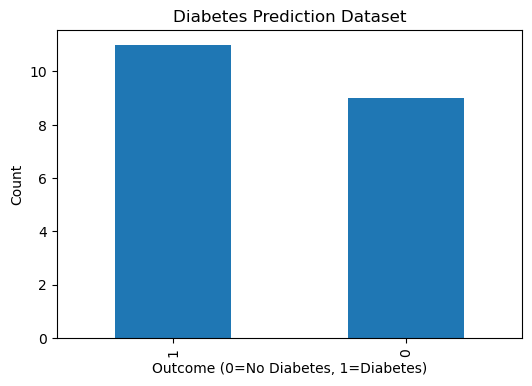

In [1]:
### import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Create Dataset
data = {
    'Pregnancies':[6,1,8,1,0,5,3,10,2,8,4,7,5,1,9,2,4,6,3,7],
    'Glucose':[148,85,183,89,137,116,78,115,197,125,110,168,139,189,166,100,120,145,130,155],
    'BloodPressure':[72,66,64,66,40,74,50,0,70,96,92,74,80,60,76,70,80,82,78,88],
    'SkinThickness':[35,29,0,23,35,0,32,0,45,0,20,25,30,23,28,20,25,30,22,35],
    'Insulin':[0,0,0,94,168,0,88,0,543,0,130,0,96,846,175,85,105,120,110,150],
    'BMI':[33.6,26.6,23.3,28.1,43.1,25.6,31.0,35.3,30.5,0.0,28.5,38.0,32.1,30.1,36.6,28.0,29.5,34.0,31.0,37.2],
    'DPF':[0.627,0.351,0.672,0.167,2.288,0.201,0.248,0.134,0.158,0.232,0.254,0.537,0.500,0.398,0.587,0.210,0.350,0.420,0.300,0.620],
    'Age':[50,31,32,21,33,30,26,29,53,54,45,34,40,28,51,24,36,42,38,55],
    'Outcome':[1,0,1,0,1,0,0,1,1,1,0,1,1,0,1,0,0,1,0,1]
}

df = pd.DataFrame(data)

print("Dataset Loaded Successfully")
print(df.head())

# Features and Target
X = df.drop('Outcome', axis=1)
y = df['Outcome']

# Split Data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train Model
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

# Test Accuracy
y_pred = model.predict(X_test)

print("\nAccuracy:", round(accuracy_score(y_test, y_pred)*100, 2), "%")

# User Input
print("\nEnter Patient Details")

preg = float(input("Pregnancies: "))
glu = float(input("Glucose: "))
bp = float(input("Blood Pressure: "))
skin = float(input("Skin Thickness: "))
ins = float(input("Insulin: "))
bmi = float(input("BMI: "))
dpf = float(input("Diabetes Pedigree Function: "))
age = float(input("Age: "))

new_patient = pd.DataFrame({
    'Pregnancies':[preg],
    'Glucose':[glu],
    'BloodPressure':[bp],
    'SkinThickness':[skin],
    'Insulin':[ins],
    'BMI':[bmi],
    'DPF':[dpf],
    'Age':[age]
})

prediction = model.predict(new_patient)

print("\n===== RESULT =====")

if prediction[0] == 1:
    print("Person is Diabetic")
else:
    print("Person is Not Diabetic")

# Graph
plt.figure(figsize=(6,4))
df['Outcome'].value_counts().plot(kind='bar')
plt.title("Diabetes Prediction Dataset")
plt.xlabel("Outcome (0=No Diabetes, 1=Diabetes)")
plt.ylabel("Count")
plt.show()